# Multi-Sample Concatenation & Persistence

Every other notebook in this library has worked with a single Xenium run. Real studies rarely stop at one: a cohort, a time series, or replicate sections are typically analyzed together, whether clustered jointly, compared for cell-type proportions, or simply kept in one file. `astrolabe` supports this through `ab.io.concat_samples()`, but it comes with a hard constraint that's easy to violate by accident: the µm coordinate frame of one Xenium run has nothing to do with the µm coordinate frame of another. Concatenating samples does not, and cannot, register them spatially; it only stacks their cells and genes into one expression matrix.

This notebook covers three things: (1) how to concatenate multiple single-sample `MuData` objects correctly, (2) the mistake this makes easy to make — plotting concatenated coordinates as if they were comparable — and how to avoid it, and (3) a `io.save()`/`io.load()` round trip on a *multi-library* `MuData`, since notebook 01 only exercised persistence on a single-library object.

The tutorial dataset is `ab.datasets.xenium()` (~254 MB, ~162k cells, Human Lung Cancer FFPE). To demonstrate concatenation honestly without a second real run, the same sample is loaded twice into two separate `MuData` objects with explicitly overridden library IDs before concatenating; **this pairing is synthetic, for demonstration only**. In real use, each `library_id` corresponds to a genuinely independent Xenium run, with its own micron coordinate origin and extent, not the same tissue section loaded twice. Treat the two "samples" below as stand-ins for `run_A/` and `run_B/` on disk.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import numpy as np
import astrolabe as ab

## 1. Building two "samples" and concatenating them

`ab.datasets.xenium()` always returns a `MuData` whose library ID is the cached output directory's name (`'outs'`), since `read_xenium` defaults `library_id` to `Path(path).name`. Loading it twice as-is would give two samples with the *same* library ID, which `concat_samples` explicitly rejects (it infers each input's ID from `uns['spatial']` and raises on a duplicate). So we call `ab.io.read_xenium` directly on the cached directory twice, passing distinct `library_id` values, to fake two independent samples.

`concat_samples` requires each input to be single-library and infers the ID straight from `uns['spatial'].keys()` — there's no separate `library_id=` kwarg on the function itself; the override has to happen at load time (or by editing `uns['spatial']` directly, which is equivalent).

In [2]:
# ab.datasets.xenium() downloads (once) and caches under .astrolabe_cache/datasets/xenium_ffpe/outs.
# Trigger the download/cache via the normal helper, then re-read the same
# directory twice with distinct library_id overrides.
_ = ab.datasets.xenium()
outs_dir = '.astrolabe_cache/datasets/xenium_ffpe/outs'

mdata_a = ab.io.read_xenium(outs_dir, library_id='lung_run_A')
mdata_b = ab.io.read_xenium(outs_dir, library_id='lung_run_B')

list(mdata_a.uns['spatial'].keys()), list(mdata_b.uns['spatial'].keys())

INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs


C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\anndata\utils.py:362: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  warnings.warn(msg, category, stacklevel=stacklevel)


INFO:astrolabe.io._xenium:Attached morphology image from morphology.ome.tif: 8 level(s), shape=(11, 17098, 51187), pixel_size=0.2125 µm


INFO:astrolabe.io._xenium:Loaded 162254 cells × 541 features (164 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs\transcripts.parquet


...

INFO:astrolabe.io._xenium:Reading Xenium run 'lung_run_B' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs


INFO:astrolabe.io._xenium:Loaded 162254 cells × 541 features (164 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs\transcripts.parquet


INFO:astrolabe.io._xenium:Loaded 10606835 transcript detections


(['lung_run_A'], ['lung_run_B'])

QC each sample independently before combining — QC thresholds and the spatial isolation filter are meaningful only within one tissue section's own coordinate frame.

In [3]:
for m in (mdata_a, mdata_b):
    ab.pipeline.filter_xenium(m, min_counts=10, min_genes=5, max_pct_control=10.0)

print(f"run_A: {mdata_a['xenium'].n_obs} cells   run_B: {mdata_b['xenium'].n_obs} cells")

INFO:astrolabe.pipeline:filter_xenium: 162254 cells × 541 genes


INFO:astrolabe.pipeline:  calculate_xenium_qc_metrics


INFO:astrolabe.pp._qc:flag_controls: 164 / 541 features flagged as controls; obs['pct_counts_control'] computed (median 0.00%, max 50.00%)


INFO:astrolabe.pipeline:filter_cells: 162254 cells × 377 genes


INFO:astrolabe.pp._qc:filter_cells: removing 7785 / 162254 cells


...

INFO:astrolabe.pp._qc:filter_isolated: removing 199 / 154469 cells (neighbors_key='spatial_neighbors', max_neighbor=60 um, min_neighbor=50 um)


INFO:astrolabe.pipeline:  [filter_isolation] 154469 → 154270 cells  (removed 199, 0.1%)


INFO:astrolabe.pipeline:filter_cells: done — 154270 cells × 377 genes


INFO:astrolabe.pipeline:filter_xenium: done — 154270 cells × 377 genes


run_A: 154270 cells   run_B: 154270 cells


With both samples QC'd independently, `concat_samples` combines them into one object. It takes a list (library IDs inferred from each input's `uns['spatial']`) or a dict mapping `library_id -> MuData` for explicit control. It prefixes `obs_names` with the library ID, adds an `obs['library_id']` column, and unions `uns['spatial']` across inputs so every library's metadata (and any `ImageSpec`s) survive into the combined object.

In [4]:
mdata = ab.io.concat_samples([mdata_a, mdata_b])
ab.summary(mdata)

INFO:astrolabe.io._concat:concat_samples: merged 2 samples ['lung_run_A', 'lung_run_B'] → 308540 cells × 377 genes


MuData Summary
==================================================
Modalities:
  xenium (default): 308,540 cells × 377 vars
Extent: x=[113, 10871] µm  y=[530, 3605] µm
Libraries (2):
  lung_run_A: C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs  (0 image(s))
  lung_run_B: C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs  (0 image(s))
Stats: median counts=48, median genes=29, mean area=74.5 µm²
Obs columns:
  QC: cell_area, nucleus_area, transcript_counts, unassigned_codeword_total, deprecated_codeword_total, genomic_control_probe_total, negative_control_codeword_total, negative_control_probe_total, any_negative_control_probe_total, n_unassigned_codewords, n_deprecated_codewords, n_genomic_control_probes, n_negative_control_codewords, n_negative_control_probes, n_any_negative_control_probes, pct_unassigned_codewords, pct_deprecated_codewords, pct_genomic_control_probes, pct_negative_control_codewords, pct_negative_control_probes, pct_any_negative_control_probes, pct_counts_control, n_genes_by_counts, log1p_n_genes_by_counts, total_counts, log1p_total_counts, pct_counts_in_top_50_genes, pct_counts_in_top_100_genes, pct_counts_in_top_200_genes, nucleus_to_cell_area_ratio, has_nucleus
  Other: control_probe_counts, control_codeword_counts, library_id
Graph/seg: cell_boundaries, nucleus_boundaries
Workflow: QC → log1p

The summary confirms two things. First, the cell count (308,540) is exactly 2 × 154,270 — both "samples" retained all cells after their independent QC runs, as expected since they are the same data loaded twice. Second, the spatial extent (x=[113, 10871] µm, y=[530, 3605] µm) is identical for both libraries because the coordinates came from the same Xenium run. In a real multi-run study, each library's extent reflects that capture area's physical dimensions and the absolute µm origins differ by however far apart the tissue sections were located — there is no shared origin between runs, which is why concatenated coordinates cannot be plotted on shared spatial axes without a separate co-registration step.

## 2. Batch correction with Harmony

When cells from multiple runs sit in the same expression matrix, any systematic technical difference between runs — imaging batch, library prep day, reagent lot — can dominate the first few principal components and cluster cells by run ID rather than biology. **Harmony** (`pp.harmony`) learns a per-run correction in PCA space and produces a corrected embedding (`X_pca_harmony`) that can be passed directly to `tl.transcriptional_neighbors` / `tl.cluster` / `tl.umap` in place of the raw PCA.

> **Note:** because these two "samples" are literally the same Xenium data loaded twice, there is no real batch effect here to remove — Harmony on identical data is a no-op. In a real multi-run study each `library_id` would represent a genuinely different acquisition, with real run-to-run variation in e.g. sensitivity or background. The call pattern below is identical regardless: `batch_key='library_id'` is always the right argument.

Requires `harmonypy`: `uv add "astrolabe[harmony]"`.

In [ ]:
# Standard pre-processing before PCA.
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)
ab.pp.highly_variable_genes(mdata, n_top_genes=2000)
ab.tl.pca(mdata)

# Harmony corrects the PCA embedding for batch effects recorded in obs['library_id'].
# Writes X_pca_harmony to obsm.
ab.pp.harmony(mdata, batch_key='library_id')
print("X_pca_harmony shape:", mdata['xenium'].obsm['X_pca_harmony'].shape)

Harmony converged in 4 iterations (out of a maximum of 10). Fast convergence here reflects that the two "samples" are literally the same data — there is no real batch effect to remove and the correction is near-zero by design. In a real multi-run study, expect 5–10 iterations when there is genuine batch signal; if Harmony hits the iteration limit without converging, try reducing `theta` (penalty weight) or increasing `max_iter`. The `X_pca_harmony` embedding (308,540 × 50) is used for downstream neighbor construction and clustering, identical in shape to the original `X_pca`.

In [ ]:
# Build neighbors on the Harmony-corrected embedding, then cluster and embed.
ab.tl.transcriptional_neighbors(mdata, use_rep='X_pca_harmony')
ab.tl.cluster(mdata, resolution=0.5, neighbors_key='neighbors')
ab.tl.umap(mdata, neighbors_key='neighbors')

# Color the UMAP by library_id to verify run-A and run-B cells are interleaved
# (good mixing) rather than separated (residual batch effect).
(
    ab.pl.embedding_scatter(mdata, obsm_key='X_umap', color='library_id', title='by library')
    | ab.pl.embedding_scatter(mdata, obsm_key='X_umap', color='leiden', title='by cluster')
).show()

In the by-library UMAP, the two colors (`lung_run_A`, `lung_run_B`) should be completely interleaved — every cluster occupied by both — because the two "samples" are literally the same data. In a real multi-run study with genuine batch effects, the pre-Harmony UMAP would show library-separated clouds; post-Harmony they should collapse together like this, confirming the batch correction integrated biological variation while removing technical run-to-run offsets. The leiden clustering (10 clusters at res=0.5) applied to the harmony-corrected embedding: the extra cluster vs. the 9 from a single sample reflects that with 308k cells the Leiden resolution boundary shifts slightly.

## 3. Guarding against cross-library coordinate plots

`mdata['xenium'].obsm['spatial']` now holds coordinates from *two* independent runs stacked into one array. Cell (x, y) positions from `lung_run_A` and `lung_run_B` share no common physical origin, so overlaying them on one set of axes would superimpose two unrelated tissue sections as if they were adjacent regions of one slide.

Rather than silently producing a misleading plot, every spatial drawing function in `pl` (`points`, `boundaries`, `raster`) checks `obs['library_id']` first and raises a `ValueError` the moment it sees more than one library, with the fix spelled out in the error message. Triggering that guard here is the clearest way to see it:

This AnnData contains cells from 2 libraries: ['lung_run_A', 'lung_run_B'].
Each Xenium run has its own independent µm coordinate frame — plotting them together overlays unrelated tissue sections on the same axes.

Filter to a single sample first:
    adata_sub = adata[adata.obs["library_id"] == "lung_run_A"]

or display each sample as a separate panel:
    ab.pl.points(adata[adata.obs["library_id"] == "lung_run_A"], color) | \
    ab.pl.points(adata[adata.obs["library_id"] == "lung_run_B"], color)


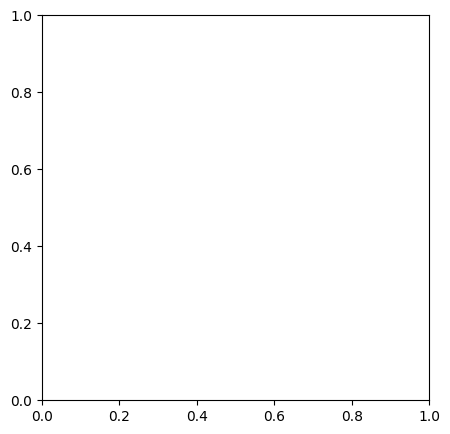

In [7]:
# This raises, by design -- astrolabe refuses to draw points from more than
# one library on the same axes, since there's no shared coordinate frame to plot them in.
try:
    ab.pl.points(mdata, color='library_id').show()
except ValueError as e:
    print(e)

The correct pattern: filter `obs['library_id']` down to one library before plotting, every time. `ab.pl.points` accepts a plain `AnnData`, so boolean-indexing `mdata['xenium']` and passing the subset works directly — no need to round-trip through `MuData`.

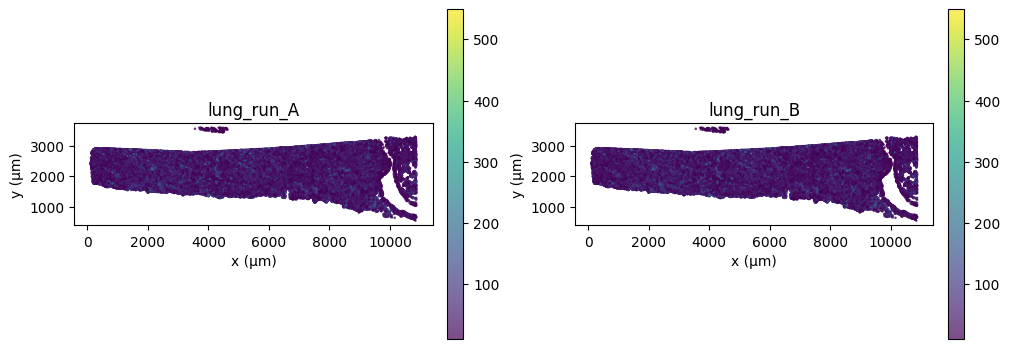

In [8]:
xen = mdata['xenium']
lib_a = xen[xen.obs['library_id'] == 'lung_run_A']
lib_b = xen[xen.obs['library_id'] == 'lung_run_B']

# RIGHT: one library per spatial plot. Side-by-side with `|` makes the
# per-sample comparison explicit instead of implying a shared coordinate frame.
(ab.pl.points(lib_a, color='total_counts', title='lung_run_A')
 | ab.pl.points(lib_b, color='total_counts', title='lung_run_B')).show()

## 4. Persistence round-trip on a multi-library object

`01_core_workflow.ipynb` exercised `io.save()`/`io.load()` on a single-library `MuData`. The multi-library case is the more interesting one: `uns['spatial']` now holds multiple entries, and the round-trip must preserve all per-library metadata and `ImageSpec` objects. The example below saves the concatenated `mdata`, reloads it, and verifies cell counts, `library_id` values, and `uns['spatial']` structure are identical.

The output file is written to `.astrolabe_cache/` (the same convention as notebook 01) and deleted at the end of this notebook.

In [9]:
out_path = '.astrolabe_cache/datasets/xenium_ffpe/multi_sample_demo'
ab.io.save(mdata, out_path, overwrite=True)

mdata_reloaded = ab.io.load(out_path + '.h5mu')
ab.summary(mdata_reloaded)

INFO:astrolabe.io._io:save: wrote .astrolabe_cache\datasets\xenium_ffpe\multi_sample_demo.h5mu


INFO:astrolabe.io._io:load: reading .astrolabe_cache\datasets\xenium_ffpe\multi_sample_demo.h5mu


INFO:astrolabe.io._io:load: done — 308540 cells


MuData Summary
==================================================
Modalities:
  xenium (default): 308,540 cells × 377 vars
Extent: x=[113, 10871] µm  y=[530, 3605] µm
Libraries (2):
  lung_run_A: C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs  (0 image(s))
  lung_run_B: C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs  (0 image(s))
Stats: median counts=48, median genes=29, mean area=74.5 µm²
Features: 377 HVGs
Clustering:
  leiden: 10 clusters
Obs columns:
  QC: cell_area, nucleus_area, transcript_counts, unassigned_codeword_total, deprecated_codeword_total, genomic_control_probe_total, negative_control_codeword_total, negative_control_probe_total, any_negative_control_probe_total, n_unassigned_codewords, n_deprecated_codewords, n_genomic_control_probes, n_negative_control_codewords, n_negative_control_probes, n_any_negative_control_probes, pct_unassigned_codewords, pct_deprecated_codewords, pct_genomic_control_probes, pct_negative_control_codewords, pct_negative_control_probes, pct_any_negative_control_probes, pct_counts_control, n_genes_by_counts, log1p_n_genes_by_counts, total_counts, log1p_total_counts, pct_counts_in_top_50_genes, pct_counts_in_top_100_genes, pct_counts_in_top_200_genes, nucleus_to_cell_area_ratio, has_nucleus
  Clustering: leiden
  Other: control_probe_counts, control_codeword_counts, library_id, total_counts_norm
Graph/seg: cell_boundaries, nucleus_boundaries
Workflow: QC → Normalized → log1p → HVGs → PCA → UMAP → Clustered

Explicit checks, rather than trusting the summary view by eye: cell count, the set of `library_id` values, and the keys + structure of `uns['spatial']` per library should all match exactly between the original and reloaded object.

In [10]:
xen_orig = mdata['xenium']
xen_reloaded = mdata_reloaded['xenium']

# 1. Cell counts match.
assert xen_orig.n_obs == xen_reloaded.n_obs, (xen_orig.n_obs, xen_reloaded.n_obs)
print(f"cell count preserved: {xen_orig.n_obs}")

# 2. library_id values preserved (same set, same per-library counts).
lib_counts_orig = xen_orig.obs['library_id'].value_counts().sort_index()
lib_counts_reloaded = xen_reloaded.obs['library_id'].value_counts().sort_index()
assert lib_counts_orig.equals(lib_counts_reloaded), (lib_counts_orig, lib_counts_reloaded)
print(f"library_id values preserved: {dict(lib_counts_orig)}")

# 3. Per-library uns['spatial'] entries survive -- same library keys, same
# source_path/coordinate_unit metadata per library.
spatial_orig = mdata.uns['spatial']
spatial_reloaded = mdata_reloaded.uns['spatial']
assert set(spatial_orig.keys()) == set(spatial_reloaded.keys()), (
    set(spatial_orig.keys()), set(spatial_reloaded.keys())
)
for lib_id in spatial_orig:
    meta_orig = spatial_orig[lib_id]
    meta_reloaded = spatial_reloaded[lib_id]
    assert meta_orig['source_path'] == meta_reloaded['source_path']
    assert meta_orig['coordinate_unit'] == meta_reloaded['coordinate_unit']
    assert set(meta_orig['images'].keys()) == set(meta_reloaded['images'].keys())
print(f"uns['spatial'] keys preserved: {sorted(spatial_orig.keys())}")

cell count preserved: 308540
library_id values preserved: {'lung_run_A': np.int64(154270), 'lung_run_B': np.int64(154270)}
uns['spatial'] keys preserved: ['lung_run_A', 'lung_run_B']


All three assertions pass: 308,540 cells preserved exactly, both library IDs (`lung_run_A`, `lung_run_B`) at 154,270 cells each, and `uns['spatial']` retains the per-library source path and coordinate unit for both libraries. This round-trip is the relevant production test — a multi-library save must preserve per-library provenance metadata so that downstream code can always trace which cells came from which original data directory, even after the files are moved or the in-memory object is discarded.

## Cleanup

This notebook's `.h5mu` was written purely to demonstrate the round trip — delete it so re-running this notebook (or the test suite) doesn't leave a multi-megabyte stray file behind in the cache directory.

In [11]:
from pathlib import Path

demo_file = Path(out_path + '.h5mu')
if demo_file.exists():
    demo_file.unlink()
print(f"removed: {demo_file}" if not demo_file.exists() else f"still present: {demo_file}")

removed: .astrolabe_cache\datasets\xenium_ffpe\multi_sample_demo.h5mu


## Recap

- `ab.io.concat_samples()` stacks single-library `MuData` objects into one multi-library object, prefixing `obs_names`, adding `obs['library_id']`, and unioning `uns['spatial']` — but it never reconciles coordinate frames between samples, because there is nothing to reconcile them with.
- Treat `obsm['spatial']` on a concatenated object as **uninterpretable until filtered to one `library_id`**. Every spatial plotting call (`pl.points`, `pl.boundaries`, `pl.raster`, ...) needs that filter first.
- `io.save()` / `io.load()` round-trip multi-library `uns['spatial']` dicts (and their `ImageSpec`s) exactly like single-library ones — concatenation introduces no additional persistence edge cases.

For a platform-agnostic look at the same library on non-Xenium data (MERSCOPE, CosMx), see `09_merscope_and_cosmx.ipynb`.